<a href="https://colab.research.google.com/github/Pragatisource08/Drone-Vehicle-Detection/blob/main/Drone_vehicle_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Fri Nov 13 09:43:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
!pip -q install ultralytics opencv-python

In [4]:
import os
print(os.path.exists("video.mp4"))

True


In [5]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [6]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")   # start from the pretrained model: this is the "fine-tuning" part

results = model.train(
    data="VisDrone.yaml",
    epochs=1,            # just one pass to measure time
    imgsz=640,
    batch=16,
    fraction=0.1,        # use only 10% of the training images
    device=0,
    project="/content/ft_runs",
    name="smoke",
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.1, freeze=None, hsv_

In [7]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

results = model.train(
    data="VisDrone.yaml",
    epochs=10,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/ft_runs",
    name="run1",
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=VisDrone.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=run1, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overla

In [8]:
!nvidia-smi

Fri Nov 13 10:19:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             35W /   70W |     417MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [9]:
!pip -q install ultralytics opencv-python

In [10]:
from ultralytics import YOLO
import cv2

WEIGHTS = "/content/ft_runs/run1/weights/best.pt"
FT_VEHICLES = [3, 4, 5, 8, 9]   # car, van, truck, bus, motor

def check(conf, imgsz, save_idx=700):
    m = YOLO(WEIGHTS)
    counts = []
    for i, r in enumerate(m.predict(source="video.mp4", conf=conf, imgsz=imgsz,
                                    classes=FT_VEHICLES, stream=True, device=0, verbose=False)):
        counts.append(len(r.boxes))
        if i == save_idx:
            cv2.imwrite(f"ft_frame_conf{conf}_size{imgsz}.jpg", r.plot())
    return round(sum(counts) / len(counts), 2), max(counts)

for c, s in [(0.3, 640), (0.1, 640), (0.1, 1280), (0.1, 1920)]:
    print("FINE-TUNED conf", c, "size", s, "->", check(c, s))

FINE-TUNED conf 0.3 size 640 -> (24.06, 41)
FINE-TUNED conf 0.1 size 640 -> (52.76, 89)
FINE-TUNED conf 0.1 size 1280 -> (73.83, 163)
FINE-TUNED conf 0.1 size 1920 -> (84.52, 179)


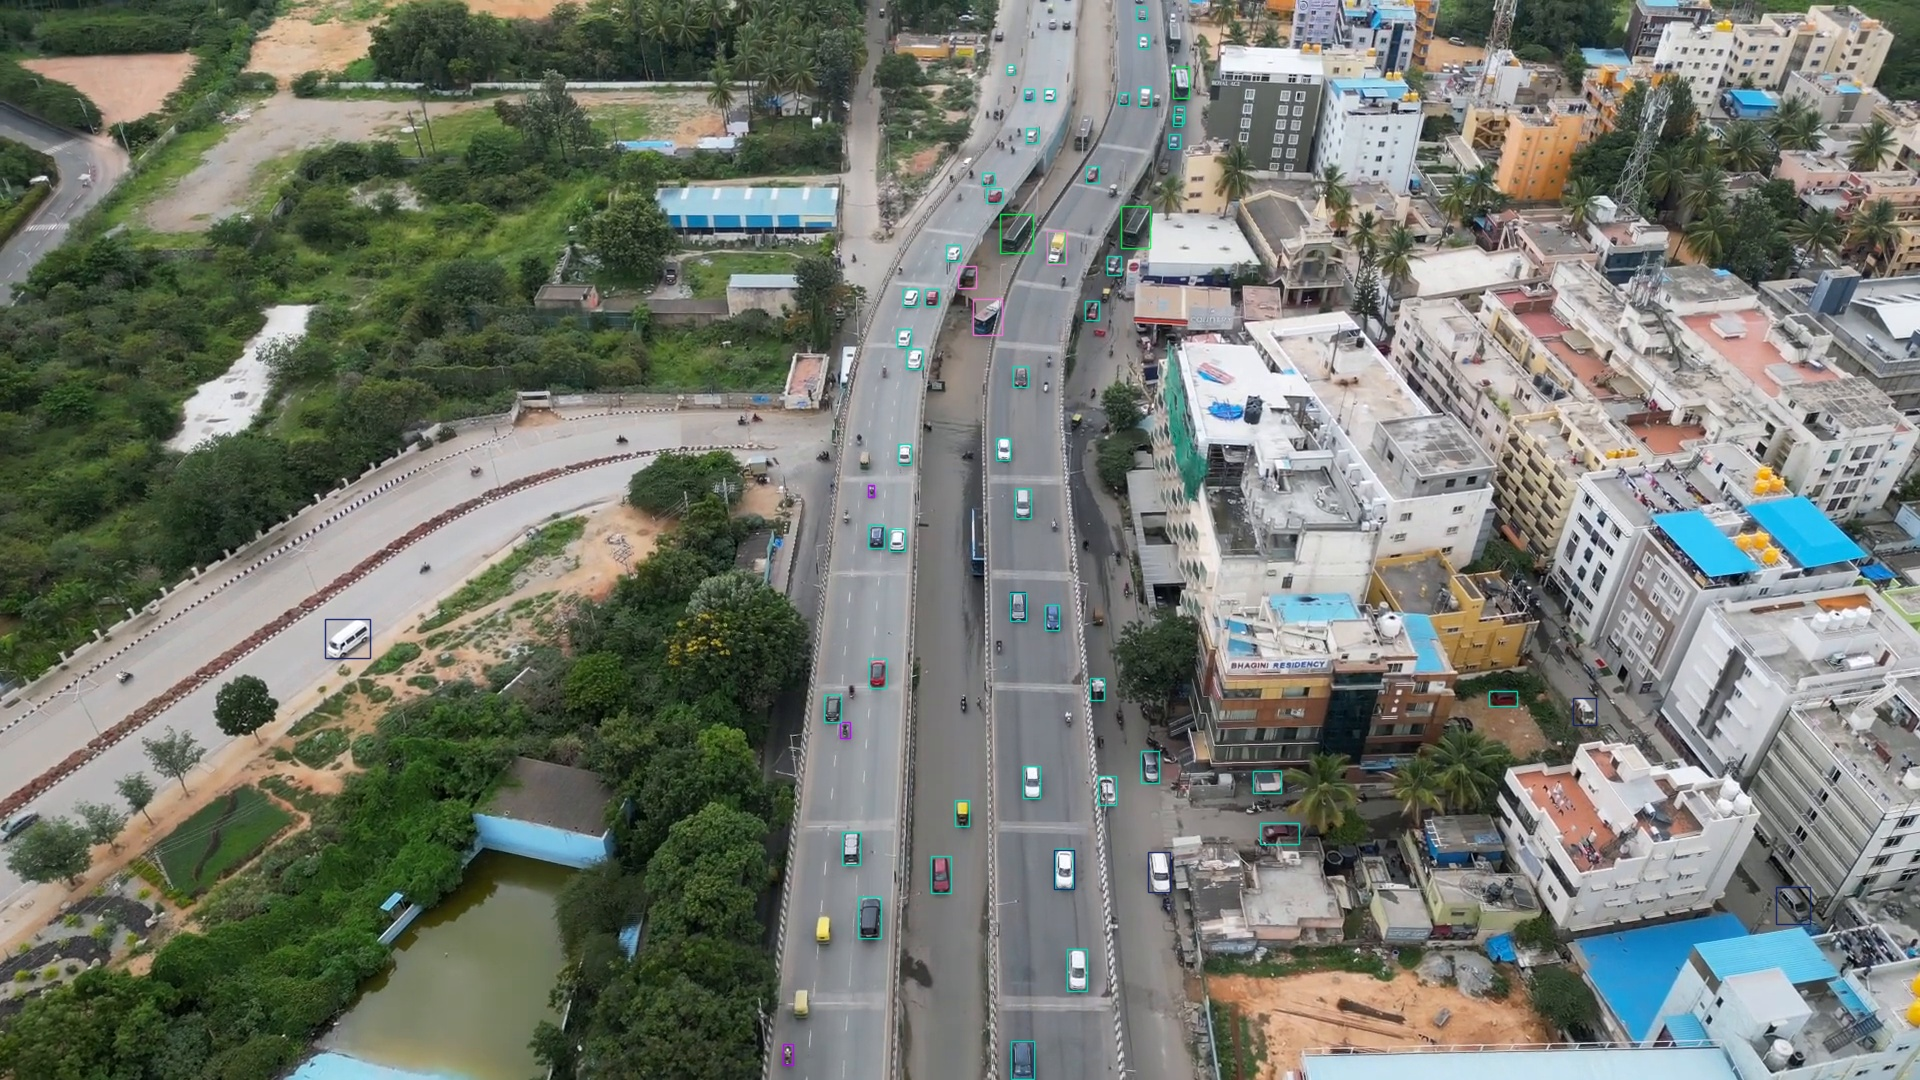

In [11]:
from ultralytics import YOLO
import cv2

WEIGHTS = "/content/ft_runs/run1/weights/best.pt"
FT_VEHICLES = [3, 4, 5, 8, 9]   # car, van, truck, bus, motor

m = YOLO(WEIGHTS)
for i, r in enumerate(m.predict(source="video.mp4", conf=0.3, imgsz=1280,
                                classes=FT_VEHICLES, stream=True, device=0, verbose=False)):
    if i == 700:
        img = r.plot(labels=False, conf=False, line_width=1)
        cv2.imwrite("clean_frame700.jpg", img)
        break

from IPython.display import Image, display
display(Image(filename="clean_frame700.jpg"))

In [12]:
from ultralytics import YOLO
from collections import defaultdict, Counter

WEIGHTS = "/content/ft_runs/run1/weights/best.pt"
FT_VEHICLES = [3, 4, 5, 8, 9]   # car, van, truck, bus, motor

m = YOLO(WEIGHTS)
frames_seen = defaultdict(int)
cls_of = {}

for r in m.track(
    source="video.mp4",
    conf=0.3,
    imgsz=1280,
    classes=FT_VEHICLES,
    tracker="bytetrack.yaml",
    persist=True,
    stream=True,
    device=0,
    verbose=False,
    save=True,
    project="/content/ft_runs",
    name="track1",
    show_labels=False,
    show_conf=False,
    line_width=1,
):
    if r.boxes.id is None:
        continue
    for tid, c in zip(r.boxes.id.int().tolist(), r.boxes.cls.int().tolist()):
        frames_seen[tid] += 1
        cls_of[tid] = c

print("total IDs:", len(frames_seen))
stable = [t for t, n in frames_seen.items() if n >= 15]   # seen for about half a second or more
print("IDs seen in >=15 frames:", len(stable))
print(Counter(m.names[cls_of[t]] for t in stable))

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 237ms
Prepared 1 package in 250ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.9s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

Results saved to /content/ft_runs/track1
total IDs: 686
IDs seen in >=15 frames: 201
Counter({'car': 110, 'motor': 61, 'van': 19, 'bus': 8, 'truck': 3})


In [13]:
for k in [5, 15, 30, 60, 120]:
    print(f">= {k} frames:", sum(1 for n in frames_seen.values() if n >= k))

>= 5 frames: 318
>= 15 frames: 201
>= 30 frames: 169
>= 60 frames: 137
>= 120 frames: 101
